## Load the dataset

In [28]:
from pathlib import Path
import pandas as pd
import numpy as np

# Main project directory
PROJECT_ROOT = Path(
    r"C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI"
)

# Define data directories
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Check paths
print("Project exists:", PROJECT_ROOT.exists())
print("Processed folder exists:", PROCESSED_DIR.exists())
print("Current working directory:", Path.cwd())

print("\nAvailable processed files:")
for file in PROCESSED_DIR.glob("*.parquet"):
    print(file.name)

Project exists: True
Processed folder exists: True
Current working directory: c:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\notebooks

Available processed files:
berlin_bicycle_calendar_features.parquet
berlin_bicycle_cleaned.parquet
berlin_bicycle_model_ready.parquet
berlin_bicycle_quality_flagged.parquet
berlin_bicycle_rolling_features.parquet
berlin_bicycle_station_features.parquet
berlin_traffic_all_years.parquet
test.parquet
train.parquet
validation.parquet


In [29]:
import pandas as pd
import numpy as np
from pathlib import Path

# Find the project root (works from the root or notebooks folder)
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Path to our Phase 2 final dataset
data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_quality_flagged.parquet"
)


if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

# Load dataset
df = pd.read_parquet(
    PROCESSED_DIR / "berlin_bicycle_station_features.parquet"
)
print("Dataset loaded successfully!")
print("Number of observations:", len(df))
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of observations: 2216184
Number of columns: 17


,timestamp,station_id,bicycle_count,year,extreme_threshold,extreme_flag,hour,day_of_week,month,day_of_year,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2023-01-01 00:00:00,01-MI-AL-W,6.0,2023,929.0,False,0,6,1,1,1,0.000000,1.000000,-0.781831,0.62349,0.0,1.0
1,2023-01-01 01:00:00,01-MI-AL-W,17.0,2023,929.0,False,1,6,1,1,1,0.258819,0.965926,-0.781831,0.62349,0.0,1.0
2,2023-01-01 02:00:00,01-MI-AL-W,17.0,2023,929.0,False,2,6,1,1,1,0.500000,0.866025,-0.781831,0.62349,0.0,1.0
3,2023-01-01 03:00:00,01-MI-AL-W,13.0,2023,929.0,False,3,6,1,1,1,0.707107,0.707107,-0.781831,0.62349,0.0,1.0
4,2023-01-01 04:00:00,01-MI-AL-W,12.0,2023,929.0,False,4,6,1,1,1,0.866025,0.500000,-0.781831,0.62349,0.0,1.0


In [4]:
# Required columns
required_columns = [
    "timestamp",
    "station_id",
    "bicycle_count"
]

# Check that all required columns exist
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert to appropriate types
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

df["station_id"] = df["station_id"].astype("string")

df["bicycle_count"] = pd.to_numeric(
    df["bicycle_count"], errors="coerce"
)

# Display schema
print("Dataset information:")
df.info()

print("\nTimestamp range:")
print("First:", df["timestamp"].min())
print("Last:", df["timestamp"].max())

print("\nNumber of stations:")
print(df["station_id"].nunique())

print("\nAvailable columns:")
print(df.columns.tolist())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2216184 entries, 0 to 2216183
Data columns (total 17 columns):
 #   Column             Dtype         
---  ------             -----         
 0   timestamp          datetime64[us]
 1   station_id         string        
 2   bicycle_count      float64       
 3   year               int32         
 4   extreme_threshold  float64       
 5   extreme_flag       bool          
 6   hour               int32         
 7   day_of_week        int32         
 8   month              int32         
 9   day_of_year        int32         
 10  is_weekend         int64         
 11  hour_sin           float64       
 12  hour_cos           float64       
 13  dow_sin            float64       
 14  dow_cos            float64       
 15  month_sin          float64       
 16  month_cos          float64       
dtypes: bool(1), datetime64[us](1), float64(8), int32(5), int64(1), string(1)
memory usage: 252.2 MB

Timestamp range:
First: 2017-01-01

In [3]:
# Missing values in essential fields
print("Missing values:")
print(df[required_columns].isna().sum())

# Duplicate station-timestamp combinations
duplicate_count = df.duplicated(
    subset=["station_id", "timestamp"]
).sum()

print("\nDuplicate station-hour records:", duplicate_count)

# Negative bicycle counts
negative_count = (df["bicycle_count"] < 0).sum()

print("Negative bicycle counts:", negative_count)

# Fractional bicycle counts
fractional_count = (
    df["bicycle_count"].notna()
    & (df["bicycle_count"] % 1 != 0)
).sum()

print("Fractional bicycle counts:", fractional_count)

# Observations not aligned to exact hours
non_hourly = (
    (df["timestamp"].dt.minute != 0)
    | (df["timestamp"].dt.second != 0)
).sum()

print("Non-hourly timestamps:", non_hourly)

# Previous extreme flags
if "extreme_flag" in df.columns:
    print(
        "Previously flagged extreme observations:",
        df["extreme_flag"].sum()
    )

# Check timezone information
print("Timestamp timezone:", df["timestamp"].dt.tz)

Missing values:
timestamp        0
station_id       0
bicycle_count    0
dtype: int64

Duplicate station-hour records: 0
Negative bicycle counts: 0
Fractional bicycle counts: 0
Non-hourly timestamps: 0
Previously flagged extreme observations: 153
Timestamp timezone: None


In [ ]:
# Sort observations by station and timestamp
df = df.sort_values(
    by=["station_id", "timestamp"],
    kind="stable"
).reset_index(drop=True)

print("Dataset sorted successfully!")

display(
    df[["station_id", "timestamp", "bicycle_count"]].head(10)
)

Dataset sorted successfully!


,station_id,timestamp,bicycle_count
0,01-MI-AL-W,2023-01-01 00:00:00,6.0
1,01-MI-AL-W,2023-01-01 01:00:00,17.0
2,01-MI-AL-W,2023-01-01 02:00:00,17.0
3,01-MI-AL-W,2023-01-01 03:00:00,13.0
4,01-MI-AL-W,2023-01-01 04:00:00,12.0
5,01-MI-AL-W,2023-01-01 05:00:00,12.0
6,01-MI-AL-W,2023-01-01 06:00:00,11.0
7,01-MI-AL-W,2023-01-01 07:00:00,7.0
8,01-MI-AL-W,2023-01-01 08:00:00,6.0
9,01-MI-AL-W,2023-01-01 09:00:00,17.0


## Create calendar features

In [30]:
import numpy as np
import pandas as pd

# Use local Berlin time for calendar features
ts = df["timestamp"]

if ts.isna().any():
    raise ValueError("Missing timestamps must be resolved first.")

# If timestamps are timezone-aware, convert to Berlin time
if ts.dt.tz is not None:
    ts = ts.dt.tz_convert("Europe/Berlin")

# Basic calendar features
df["hour"] = ts.dt.hour
df["day_of_week"] = ts.dt.dayofweek
df["month"] = ts.dt.month
df["year"] = ts.dt.year
df["day_of_year"] = ts.dt.dayofyear

# Weekend indicator
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

# Inspect the new features
calendar_columns = [
    "timestamp",
    "hour",
    "day_of_week",
    "month",
    "year",
    "day_of_year",
    "is_weekend"
]

display(df[calendar_columns].head(10))

,timestamp,hour,day_of_week,month,year,day_of_year,is_weekend
0,2023-01-01 00:00:00,0,6,1,2023,1,1
1,2023-01-01 01:00:00,1,6,1,2023,1,1
2,2023-01-01 02:00:00,2,6,1,2023,1,1
3,2023-01-01 03:00:00,3,6,1,2023,1,1
4,2023-01-01 04:00:00,4,6,1,2023,1,1
5,2023-01-01 05:00:00,5,6,1,2023,1,1
6,2023-01-01 06:00:00,6,6,1,2023,1,1
7,2023-01-01 07:00:00,7,6,1,2023,1,1
8,2023-01-01 08:00:00,8,6,1,2023,1,1
9,2023-01-01 09:00:00,9,6,1,2023,1,1


In [11]:
# Hour: 24-hour cycle
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

# Day of week: 7-day cycle
df["dow_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)

df["dow_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

# Month: 12-month cycle
df["month_sin"] = np.sin(
    2 * np.pi * (df["month"] - 1) / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * (df["month"] - 1) / 12
)

# Inspect cyclical features
cyclical_columns = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

display(df[cyclical_columns].head(10))

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,0.000000,1.000000e+00,-0.781831,0.62349,0.0,1.0
1,0.258819,9.659258e-01,-0.781831,0.62349,0.0,1.0
2,0.500000,8.660254e-01,-0.781831,0.62349,0.0,1.0
3,0.707107,7.071068e-01,-0.781831,0.62349,0.0,1.0
4,0.866025,5.000000e-01,-0.781831,0.62349,0.0,1.0
5,0.965926,2.588190e-01,-0.781831,0.62349,0.0,1.0
6,1.000000,6.123234e-17,-0.781831,0.62349,0.0,1.0
7,0.965926,-2.588190e-01,-0.781831,0.62349,0.0,1.0
8,0.866025,-5.000000e-01,-0.781831,0.62349,0.0,1.0
9,0.707107,-7.071068e-01,-0.781831,0.62349,0.0,1.0


In [ ]:
import matplotlib.pyplot as plt

hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

plt.figure(figsize=(11, 5))

plt.plot(
    hours,
    hour_sin,
    label="Hour Sine",
    linewidth=2
)

plt.plot(
    hours,
    hour_cos,
    label="Hour Cosine",
    linewidth=2
)

plt.xlabel("Hour of Day")
plt.ylabel("Encoded Value")
plt.title("Cyclical Encoding of Hour")
plt.xticks(np.arange(0, 24, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [13]:
# Confirm that calendar and cyclical features are valid
new_features = [
    "hour",
    "day_of_week",
    "month",
    "year",
    "day_of_year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

print("Missing values in new features:")
print(df[new_features].isna().sum())

# Validate calendar ranges
assert df["hour"].between(0, 23).all()
assert df["day_of_week"].between(0, 6).all()
assert df["month"].between(1, 12).all()
assert df["is_weekend"].isin([0, 1]).all()

# Validate cyclical transformations
for sine_col, cosine_col in [
    ("hour_sin", "hour_cos"),
    ("dow_sin", "dow_cos"),
    ("month_sin", "month_cos")
]:
    assert np.allclose(
        df[sine_col]**2 + df[cosine_col]**2,
        1.0
    )

print("\nAll feature engineering checks passed!")
print("Current dataset shape:", df.shape)

Missing values in new features:
hour           0
day_of_week    0
month          0
year           0
day_of_year    0
is_weekend     0
hour_sin       0
hour_cos       0
dow_sin        0
dow_cos        0
month_sin      0
month_cos      0
dtype: int64

All feature engineering checks passed!
Current dataset shape: (2216184, 17)


In [31]:
output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_calendar_features.parquet"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(output_path, index=False)

print("Calendar features saved successfully!")
print("File:", output_path)
print("Shape:", df.shape)

Calendar features saved successfully!
File: C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_calendar_features.parquet
Shape: (2216184, 17)


## 3.3 Station Identity Encoding

In [32]:
# Inspect station identities
print("Number of unique stations:")
print(df["station_id"].nunique())

print("\nStation identifiers:")
print(sorted(df["station_id"].dropna().unique()))

print("\nObservations per station:")
station_counts = (
    df.groupby("station_id", observed=True)
    .size()
    .sort_values(ascending=False)
)

display(station_counts.to_frame("observations"))

Number of unique stations:
35

Station identifiers:
['01-MI-AL-W', '02-MI-JAN-N', '02-MI-JAN-S', '03-MI-SAN-O', '03-MI-SAN-W', '04-MI-NO', '05-FK-OBB-O', '05-FK-OBB-W', '06-FK-FRA-O', '06-FK-FRA-W', '07-FK-ST', '09-PA-SA-S', '10-PA-BER-N', '10-PA-BER-S', '11-PA-SE-N', '12-PA-SCH', '13-CW-PRI', '14-CW-JU-O', '14-CW-JU-W', '15-SP-KLO-N', '15-SP-KLO-S', '16-SP-NO-O', '16-SP-NO-W', '17-SZ-BRE-O', '17-SZ-BRE-W', '18-TS-YOR-O', '18-TS-YOR-W', '19-TS-MON', '20-TS-MAR-N', '20-TS-MAR-S', '21-NK-MAY', '23-TK-KAI', '24-MH-ALB', '26-LI-PUP', '27-RE-MAR']

Observations per station:


,observations
station_id,
24-MH-ALB,78881
12-PA-SCH,78880
27-RE-MAR,78879
10-PA-BER-N,78879
17-SZ-BRE-O,78879
20-TS-MAR-N,78879
15-SP-KLO-S,78879
02-MI-JAN-N,78879
13-CW-PRI,78879


In [16]:
# Convert station identifiers to strings
df["station_id"] = (
    df["station_id"]
    .astype("string")
    .str.strip()
)

# Check for missing or empty identifiers
missing_stations = (
    df["station_id"].isna()
    | df["station_id"].eq("").fillna(False)
)

print("Missing station identifiers:", missing_stations.sum())

if missing_stations.any():
    raise ValueError(
        "Missing station IDs detected. "
        "Resolve them before continuing."
    )

print("Station identifiers validated successfully!")

Missing station identifiers: 0
Station identifiers validated successfully!


In [17]:
# Convert station IDs into categorical variables
df["station_id"] = df["station_id"].astype("category")

# Inspect result
print("Station ID data type:", df["station_id"].dtype)

print(
    "Number of categories:",
    len(df["station_id"].cat.categories)
)

print("\nFirst 10 station observations:")
display(df[["timestamp", "station_id", "bicycle_count"]].head(10))

Station ID data type: category
Number of categories: 35

First 10 station observations:


,timestamp,station_id,bicycle_count
0,2023-01-01 00:00:00,01-MI-AL-W,6.0
1,2023-01-01 01:00:00,01-MI-AL-W,17.0
2,2023-01-01 02:00:00,01-MI-AL-W,17.0
3,2023-01-01 03:00:00,01-MI-AL-W,13.0
4,2023-01-01 04:00:00,01-MI-AL-W,12.0
5,2023-01-01 05:00:00,01-MI-AL-W,12.0
6,2023-01-01 06:00:00,01-MI-AL-W,11.0
7,2023-01-01 07:00:00,01-MI-AL-W,7.0
8,2023-01-01 08:00:00,01-MI-AL-W,6.0
9,2023-01-01 09:00:00,01-MI-AL-W,17.0


In [18]:
# Select up to 5 unique stations for demonstration
sample_stations = (
    df["station_id"]
    .astype("string")
    .drop_duplicates()
    .head(5)
)

# Create a one-hot encoding demonstration
one_hot_preview = pd.get_dummies(
    sample_stations,
    prefix="station",
    dtype="uint8"
)

display(one_hot_preview)

,station_01-MI-AL-W,station_02-MI-JAN-N,station_02-MI-JAN-S,station_03-MI-SAN-O,station_03-MI-SAN-W
0,1,0,0,0,0
26296,0,1,0,0,0
105175,0,0,1,0,0
183656,0,0,0,1,0
262506,0,0,0,0,1


In [19]:
# Validate categorical encoding
assert str(df["station_id"].dtype) == "category"

assert df["station_id"].notna().all()

assert (
    df["station_id"].nunique()
    == len(df["station_id"].cat.categories)
)

print("Station encoding validation passed!")

print("Total stations:", df["station_id"].nunique())
print("Dataset shape:", df.shape)

Station encoding validation passed!
Total stations: 35
Dataset shape: (2216184, 17)


In [33]:
# Output file
output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_station_features.parquet"
)

# Save
df.to_parquet(output_path, index=False)

print("Dataset saved successfully!")
print("Location:", output_path)
print("Shape:", df.shape)

Dataset saved successfully!
Location: C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_station_features.parquet
Shape: (2216184, 17)


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

# Input dataset from Step 3.3
input_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_station_features.parquet"
)

df = pd.read_parquet(input_path)

# Ensure correct data types
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Sort by station and timestamp
df = df.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Number of stations:", df["station_id"].nunique())

display(df.head())

Dataset loaded successfully!
Shape: (2216184, 17)
Number of stations: 35


,timestamp,station_id,bicycle_count,year,extreme_threshold,extreme_flag,hour,day_of_week,month,day_of_year,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2023-01-01 00:00:00,01-MI-AL-W,6.0,2023,929.0,False,0,6,1,1,1,0.000000,1.000000,-0.781831,0.62349,0.0,1.0
1,2023-01-01 01:00:00,01-MI-AL-W,17.0,2023,929.0,False,1,6,1,1,1,0.258819,0.965926,-0.781831,0.62349,0.0,1.0
2,2023-01-01 02:00:00,01-MI-AL-W,17.0,2023,929.0,False,2,6,1,1,1,0.500000,0.866025,-0.781831,0.62349,0.0,1.0
3,2023-01-01 03:00:00,01-MI-AL-W,13.0,2023,929.0,False,3,6,1,1,1,0.707107,0.707107,-0.781831,0.62349,0.0,1.0
4,2023-01-01 04:00:00,01-MI-AL-W,12.0,2023,929.0,False,4,6,1,1,1,0.866025,0.500000,-0.781831,0.62349,0.0,1.0


## Historical Rolling Averages

In [9]:
# Define rolling windows
windows = {
    "rolling_mean_3h": "3h",
    "rolling_mean_24h": "24h",
    "rolling_mean_168h": "168h"
}

# Verify that station-hour keys are unique
assert not df.duplicated(
    ["station_id", "timestamp"]
).any(), "Duplicate station timestamps detected."

# Create rolling features
for feature_name, window in windows.items():

    df[feature_name] = np.nan

    for station, group in df.groupby(
        "station_id", observed=True, sort=False
    ):

        station_series = group.set_index(
            "timestamp"
        )["bicycle_count"]

        rolling_average = station_series.rolling(
            window=window,
            min_periods=1,
            closed="left"
        ).mean()

        df.loc[group.index, feature_name] = (
            rolling_average.to_numpy()
        )

    print(f"Created {feature_name}")

print("\nRolling feature engineering completed!")

Created rolling_mean_3h
Created rolling_mean_24h
Created rolling_mean_168h

Rolling feature engineering completed!


In [24]:
rolling_columns = [
    "rolling_mean_3h",
    "rolling_mean_24h",
    "rolling_mean_168h"
]

display_columns = [
    "station_id",
    "timestamp",
    "bicycle_count",
    *rolling_columns
]

display(
    df[display_columns].dropna(
        subset=rolling_columns
    ).head(15)
)

,station_id,timestamp,bicycle_count,rolling_mean_3h,rolling_mean_24h,rolling_mean_168h
1,01-MI-AL-W,2023-01-01 01:00:00,17.0,6.000000,6.000000,6.000000
2,01-MI-AL-W,2023-01-01 02:00:00,17.0,11.500000,11.500000,11.500000
3,01-MI-AL-W,2023-01-01 03:00:00,13.0,13.333333,13.333333,13.333333
4,01-MI-AL-W,2023-01-01 04:00:00,12.0,15.666667,13.250000,13.250000
5,01-MI-AL-W,2023-01-01 05:00:00,12.0,14.000000,13.000000,13.000000
6,01-MI-AL-W,2023-01-01 06:00:00,11.0,12.333333,12.833333,12.833333
7,01-MI-AL-W,2023-01-01 07:00:00,7.0,11.666667,12.571429,12.571429
8,01-MI-AL-W,2023-01-01 08:00:00,6.0,10.000000,11.875000,11.875000
9,01-MI-AL-W,2023-01-01 09:00:00,17.0,8.000000,11.222222,11.222222
10,01-MI-AL-W,2023-01-01 10:00:00,28.0,10.000000,11.800000,11.800000


In [25]:
missing_summary = pd.DataFrame({
    "missing_count": df[rolling_columns].isna().sum(),
    "missing_percentage": (
        df[rolling_columns].isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,missing_count,missing_percentage
rolling_mean_3h,64,0.0
rolling_mean_24h,54,0.0
rolling_mean_168h,45,0.0


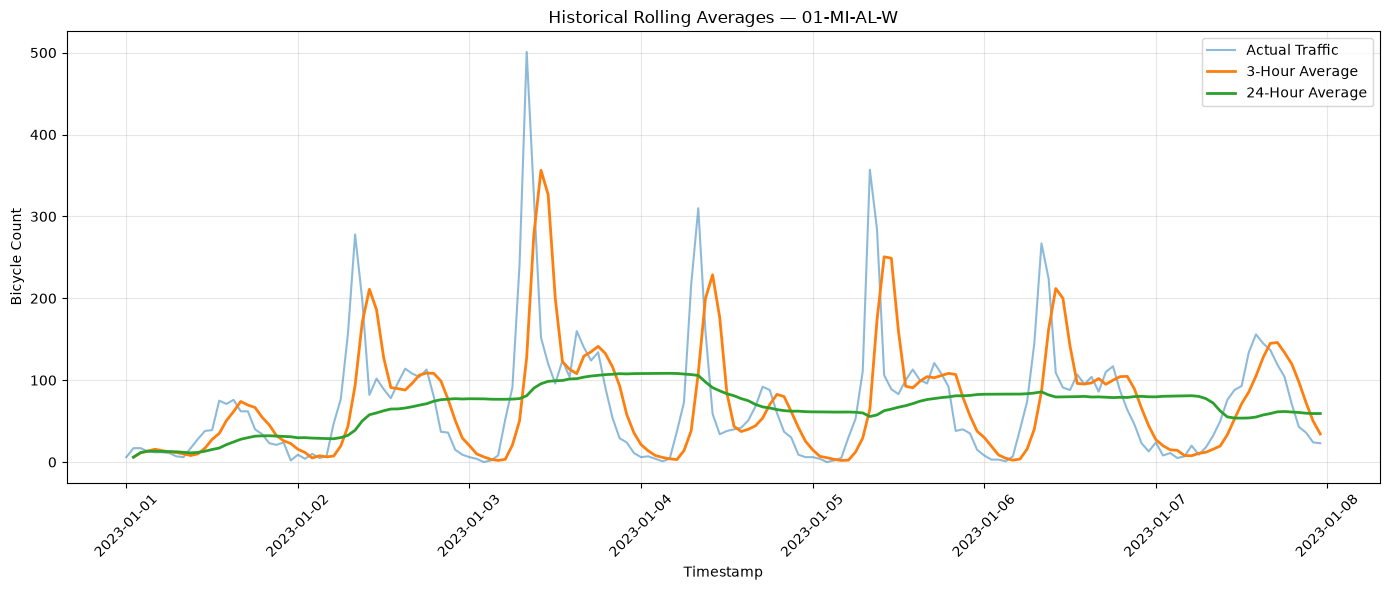

In [26]:
import matplotlib.pyplot as plt

# Choose one station
station = df["station_id"].iloc[0]

station_data = df[
    df["station_id"] == station
].copy()

# Choose first 168 observations for visualization
sample = station_data.head(168)

plt.figure(figsize=(14, 6))

plt.plot(
    sample["timestamp"],
    sample["bicycle_count"],
    label="Actual Traffic",
    alpha=0.5
)

plt.plot(
    sample["timestamp"],
    sample["rolling_mean_3h"],
    label="3-Hour Average",
    linewidth=2
)

plt.plot(
    sample["timestamp"],
    sample["rolling_mean_24h"],
    label="24-Hour Average",
    linewidth=2
)

plt.xlabel("Timestamp")
plt.ylabel("Bicycle Count")
plt.title(f"Historical Rolling Averages — {station}")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Validate rolling features
assert all(col in df.columns for col in rolling_columns)

# Rolling mean of nonnegative counts must be nonnegative
for col in rolling_columns:
    assert (df[col].dropna() >= 0).all()

print("Rolling feature validation passed!")

# Save optional rolling-feature dataset
output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_rolling_features.parquet"
)

df.to_parquet(output_path, index=False)

print("Dataset saved successfully!")
print("Location:", output_path)
print("Shape:", df.shape)

Rolling feature validation passed!
Dataset saved successfully!
Location: C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_rolling_features.parquet
Shape: (2216184, 20)


## Handle Missing Timestamps and Suspicious Observations

In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load dataset from Step 3.3
input_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "berlin_bicycle_station_features.parquet"
)

df = pd.read_parquet(input_path)

# Ensure correct data types
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

df["bicycle_count"] = pd.to_numeric(
    df["bicycle_count"], errors="coerce"
)

df["station_id"] = (
    df["station_id"]
    .astype("string")
    .str.strip()
)

# Sort observations
df = df.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

original_rows = len(df)

print("Dataset loaded!")
print("Total observations:", original_rows)
print("Number of stations:", df["station_id"].nunique())
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded!
Total observations: 2216184
Number of stations: 35
Number of columns: 17


,timestamp,station_id,bicycle_count,year,extreme_threshold,extreme_flag,hour,day_of_week,month,day_of_year,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2023-01-01 00:00:00,01-MI-AL-W,6.0,2023,929.0,False,0,6,1,1,1,0.000000,1.000000,-0.781831,0.62349,0.0,1.0
1,2023-01-01 01:00:00,01-MI-AL-W,17.0,2023,929.0,False,1,6,1,1,1,0.258819,0.965926,-0.781831,0.62349,0.0,1.0
2,2023-01-01 02:00:00,01-MI-AL-W,17.0,2023,929.0,False,2,6,1,1,1,0.500000,0.866025,-0.781831,0.62349,0.0,1.0
3,2023-01-01 03:00:00,01-MI-AL-W,13.0,2023,929.0,False,3,6,1,1,1,0.707107,0.707107,-0.781831,0.62349,0.0,1.0
4,2023-01-01 04:00:00,01-MI-AL-W,12.0,2023,929.0,False,4,6,1,1,1,0.866025,0.500000,-0.781831,0.62349,0.0,1.0


In [29]:
# Calculate time difference between consecutive
# observations at the same station
df["time_difference"] = (
    df.groupby("station_id")["timestamp"]
    .diff()
)

# Identify gaps larger than one hour
gap_mask = df["time_difference"] > pd.Timedelta(hours=1)

# Extract gap observations
gaps = df.loc[
    gap_mask,
    ["station_id", "timestamp", "time_difference"]
].copy()

# Estimate number of missing hourly slots
gaps["missing_hours"] = (
    gaps["time_difference"]
    / pd.Timedelta(hours=1)
    - 1
)

print("Number of detected time gaps:", len(gaps))

print(
    "Estimated missing hourly slots:",
    int(gaps["missing_hours"].sum())
)

print("\nLargest gaps:")
display(
    gaps.sort_values(
        "time_difference",
        ascending=False
    ).head(15)
)


Number of detected time gaps: 274
Estimated missing hourly slots: 46999

Largest gaps:


,station_id,timestamp,time_difference,missing_hours
459096,05-FK-OBB-W,2022-05-02 14:00:00,527 days 15:00:00,12662.0
392901,05-FK-OBB-O,2022-05-02 14:00:00,525 days 15:00:00,12614.0
1054166,14-CW-JU-W,2023-01-01 00:00:00,365 days 01:00:00,8760.0
1024073,14-CW-JU-O,2023-01-01 00:00:00,365 days 01:00:00,8760.0
358548,04-MI-NO,2025-12-22 11:00:00,82 days 09:00:00,1976.0
1749221,20-TS-MAR-S,2017-08-14 04:00:00,20 days 05:00:00,484.0
172703,02-MI-JAN-S,2024-10-01 14:00:00,16 days 15:00:00,398.0
2108714,26-LI-PUP,2022-09-13 08:00:00,11 days 01:00:00,264.0
1905943,23-TK-KAI,2017-07-10 05:00:00,8 days 06:00:00,197.0
2108717,26-LI-PUP,2022-09-25 15:00:00,7 days 06:00:00,173.0


In [30]:
# Replace nonfinite values with missing
df["bicycle_count"] = df["bicycle_count"].replace(
    [np.inf, -np.inf], np.nan
)

# Identify problems
missing_counts = df["bicycle_count"].isna()

negative_counts = df["bicycle_count"] < 0

fractional_counts = (
    df["bicycle_count"].notna()
    & (df["bicycle_count"] % 1 != 0)
)

# Summary
quality_summary = pd.DataFrame({
    "Problem": [
        "Missing bicycle counts",
        "Negative bicycle counts",
        "Fractional bicycle counts"
    ],
    "Number of observations": [
        missing_counts.sum(),
        negative_counts.sum(),
        fractional_counts.sum()
    ]
})

display(quality_summary)

,Problem,Number of observations
0,Missing bicycle counts,0
1,Negative bicycle counts,0
2,Fractional bicycle counts,0


In [31]:
# Check existing extreme flags
if "extreme_flag" in df.columns:

    print("Extreme flag distribution:")
    display(
        df["extreme_flag"].value_counts(
            dropna=False
        )
    )

    print("\nTop traffic observations:")

    display(
        df[
            [
                "station_id",
                "timestamp",
                "bicycle_count",
                "extreme_flag"
            ]
        ]
        .sort_values(
            "bicycle_count",
            ascending=False
        )
        .head(20)
    )

else:
    print("No extreme_flag column was found.")

    display(
        df[
            ["station_id", "timestamp", "bicycle_count"]
        ]
        .sort_values(
            "bicycle_count",
            ascending=False
        )
        .head(20)
    )

Extreme flag distribution:


extreme_flag
False    2216031
True         153
Name: count, dtype: int64


Top traffic observations:


,station_id,timestamp,bicycle_count,extreme_flag
1811931,20-TS-MAR-S,2024-10-09 10:00:00,3155.0,True
1811932,20-TS-MAR-S,2024-10-09 11:00:00,2720.0,True
56355,02-MI-JAN-N,2020-06-06 14:00:00,2167.0,True
1639055,19-TS-MON,2022-09-26 18:00:00,2023.0,True
1811933,20-TS-MAR-S,2024-10-09 12:00:00,1876.0,True
56354,02-MI-JAN-N,2020-06-06 13:00:00,1757.0,True
1638983,19-TS-MON,2022-09-23 18:00:00,1677.0,True
135235,02-MI-JAN-S,2020-06-06 15:00:00,1592.0,True
1638874,19-TS-MON,2022-09-19 05:00:00,1587.0,True
1639570,19-TS-MON,2022-10-18 05:00:00,1585.0,True


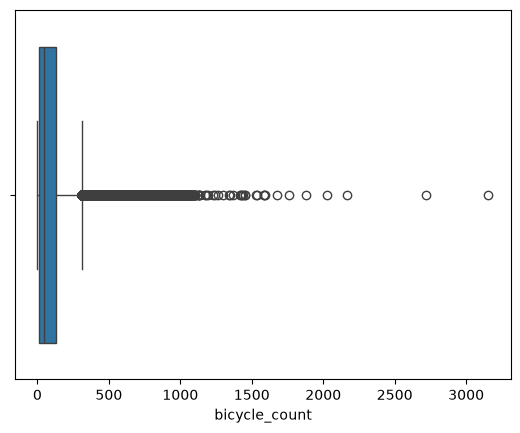

In [34]:
# Verify essential identifiers
if df[["station_id", "timestamp"]].isna().any().any():
    raise ValueError(
        "Missing station identifiers or timestamps found."
    )

if df["station_id"].eq("").any():
    raise ValueError("Empty station identifiers found.")

# Check timestamps are aligned to whole hours
not_hourly = (
    (df["timestamp"].dt.minute != 0)
    | (df["timestamp"].dt.second != 0)
    | (df["timestamp"].dt.microsecond != 0)
    | (df["timestamp"].dt.nanosecond != 0)
)

if not_hourly.any():
    display(df.loc[not_hourly].head(10))
    raise ValueError(
        "Non-hourly timestamps found. Investigate before proceeding."
    )

# Detect duplicate station-timestamp combinations
duplicates = df.duplicated(
    subset=["station_id", "timestamp"],
    keep=False
)

print("Duplicate station-hour rows:", duplicates.sum())

if duplicates.any():
    display(
        df.loc[
            duplicates,
            ["station_id", "timestamp", "bicycle_count"]
        ].head(20)
    )

    raise ValueError(
        "Duplicate station-hour observations require investigation."
    )

# Identify valid target observations
valid_target = (
    df["bicycle_count"].notna()
    & (df["bicycle_count"] >= 0)
    & (df["bicycle_count"] % 1 == 0)
)

# Keep only valid target observations
df_model = df.loc[valid_target].copy()

# Remove temporary gap diagnostics
df_model = df_model.drop(
    columns=["time_difference"],
    errors="ignore"
)

# Restore station categorical type
df_model["station_id"] = (
    df_model["station_id"].astype("category")
)

# Sort final observations
df_model = df_model.sort_values(
    ["timestamp", "station_id"]
).reset_index(drop=True)

print("Original observations:", original_rows)
print("Final valid observations:", len(df_model))
print("Excluded observations:", original_rows - len(df_model))
print("Number of stations:", df_model["station_id"].nunique())

Duplicate station-hour rows: 0
Original observations: 2216184
Final valid observations: 2216184
Excluded observations: 0
Number of stations: 35


In [15]:
# Essential features
required_features = [
    "timestamp",
    "station_id",
    "bicycle_count",
    "hour",
    "day_of_week",
    "month",
    "year",
    "day_of_year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

assert all(
    col in df_model.columns
    for col in required_features
)

assert df_model["bicycle_count"].notna().all()

assert (df_model["bicycle_count"] >= 0).all()

assert (
    df_model["bicycle_count"] % 1 == 0
).all()

assert not df_model.duplicated(
    ["station_id", "timestamp"]
).any()

# Confirm we didn't accidentally include lag
# or rolling-average features
historical_features = [
    col for col in df_model.columns
    if col.startswith(("lag_", "rolling_mean_"))
]

assert not historical_features, (
    f"Unexpected historical features: {historical_features}"
)

# Check predictor completeness
predictor_columns = [
    col for col in required_features
    if col not in ["timestamp", "bicycle_count"]
]

assert df_model[predictor_columns].notna().all().all()

print("All validation checks passed!")
print("Final shape:", df_model.shape)

display(df_model.head(10))

All validation checks passed!
Final shape: (2216184, 17)


,timestamp,station_id,bicycle_count,year,extreme_threshold,extreme_flag,hour,day_of_week,month,day_of_year,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2017-01-01,02-MI-JAN-N,6.0,2017,1219.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
1,2017-01-01,02-MI-JAN-S,5.0,2017,1208.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
2,2017-01-01,03-MI-SAN-O,4.0,2017,691.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
3,2017-01-01,03-MI-SAN-W,5.0,2017,713.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
4,2017-01-01,05-FK-OBB-O,16.0,2017,1666.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
5,2017-01-01,05-FK-OBB-W,11.0,2017,1627.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
6,2017-01-01,06-FK-FRA-O,2.0,2017,726.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
7,2017-01-01,06-FK-FRA-W,6.0,2017,706.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
8,2017-01-01,10-PA-BER-N,56.0,2017,1031.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
9,2017-01-01,10-PA-BER-S,5.0,2017,954.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0


In [16]:
# Save final modeling dataset
output_path = (
    PROCESSED_DIR / "berlin_bicycle_model_ready.parquet"
)

# Make sure the directory exists
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save dataset
df_model.to_parquet(
    output_path,
    index=False
)

print("Modeling dataset saved successfully!")
print("Location:", output_path)
print("Observations:", len(df_model))
print("Features and columns:", df_model.shape[1])

Modeling dataset saved successfully!
Location: C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_model_ready.parquet
Observations: 2216184
Features and columns: 17


##  Chronological Train/Validation/Test Split 


In [17]:
import pandas as pd
import numpy as np


df = df.copy()

# Ensure timestamp is datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Sort chronologically
df = df.sort_values(
    by=["timestamp", "station_id"]
).reset_index(drop=True)

# Check the dataset
print("Dataset shape:", df.shape)
print("Earliest timestamp:", df["timestamp"].min())
print("Latest timestamp:", df["timestamp"].max())

df.head()

Dataset shape: (2216184, 17)
Earliest timestamp: 2017-01-01 00:00:00
Latest timestamp: 2025-12-31 23:00:00


,timestamp,station_id,bicycle_count,year,extreme_threshold,extreme_flag,hour,day_of_week,month,day_of_year,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2017-01-01,02-MI-JAN-N,6.0,2017,1219.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
1,2017-01-01,02-MI-JAN-S,5.0,2017,1208.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
2,2017-01-01,03-MI-SAN-O,4.0,2017,691.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
3,2017-01-01,03-MI-SAN-W,5.0,2017,713.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0
4,2017-01-01,05-FK-OBB-O,16.0,2017,1666.0,False,0,6,1,1,1,0.0,1.0,-0.781831,0.62349,0.0,1.0


In [21]:
# Extract unique dates
unique_dates = pd.DatetimeIndex(
    df["timestamp"].dt.normalize().unique()
).sort_values()

# Number of unique dates
n_dates = len(unique_dates)

# Calculate split positions
train_end_idx = int(n_dates * 0.70)
val_end_idx = int(n_dates * 0.85)

# Determine date boundaries
val_start_date = unique_dates[train_end_idx]
test_start_date = unique_dates[val_end_idx]

print("Validation starts:", val_start_date)
print("Testing starts:", test_start_date)

Validation starts: 2023-04-20 00:00:00
Testing starts: 2024-08-25 00:00:00


In [22]:
# Training data
train_df = df[
    df["timestamp"] < val_start_date
].copy()

# Validation data
val_df = df[
    (df["timestamp"] >= val_start_date) &
    (df["timestamp"] < test_start_date)
].copy()

# Testing data
test_df = df[
    df["timestamp"] >= test_start_date
].copy()

In [23]:
# Check dataset sizes
total = len(df)

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    percentage = len(subset) / total * 100

    print(f"\n{name} dataset")
    print("Rows:", len(subset))
    print(f"Percentage: {percentage:.2f}%")
    print("Start:", subset["timestamp"].min())
    print("End:", subset["timestamp"].max())
    print("Stations:", subset["station_id"].nunique())


Training dataset
Rows: 1426327
Percentage: 64.36%
Start: 2017-01-01 00:00:00
End: 2023-04-19 23:00:00
Stations: 30

Validation dataset
Rows: 379779
Percentage: 17.14%
Start: 2023-04-20 00:00:00
End: 2024-08-24 23:00:00
Stations: 35

Testing dataset
Rows: 410078
Percentage: 18.50%
Start: 2024-08-25 00:00:00
End: 2025-12-31 23:00:00
Stations: 35


In [24]:
# Verify all datasets contain observations
assert all(
    len(part) > 0
    for part in [train_df, val_df, test_df]
)

# Check chronological order
assert (
    train_df["timestamp"].max()
    < val_df["timestamp"].min()
)

assert (
    val_df["timestamp"].max()
    < test_df["timestamp"].min()
)

# Check that no rows were lost
assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(df)
)

print("All chronological split checks passed!")

All chronological split checks passed!


In [25]:
from pathlib import Path

# Output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save datasets
train_df.to_parquet(
    output_dir / "train.parquet",
    index=False
)

val_df.to_parquet(
    output_dir / "validation.parquet",
    index=False
)

test_df.to_parquet(
    output_dir / "test.parquet",
    index=False
)

print("Training, validation, and testing datasets saved!")

Training, validation, and testing datasets saved!


In [38]:
# Stations not present in training
train_stations = set(train_df["station_id"])

unseen_val = set(val_df["station_id"]) - train_stations
unseen_test = set(test_df["station_id"]) - train_stations

print("Unseen validation stations:", sorted(unseen_val))
print("Unseen testing stations:", sorted(unseen_test))

# Check historical rolling features
rolling_cols = [
    col for col in df.columns
    if "rolling" in col.lower()
    or "historical" in col.lower()
    or "moving" in col.lower()
]

print("\nRolling features:", rolling_cols)

# Identify missing values in each dataset
print("\nTraining missing values:")
print(train_df.isna().sum()[lambda s: s > 0])

print("\nValidation missing values:")
print(val_df.isna().sum()[lambda s: s > 0])

print("\nTesting missing values:")
print(test_df.isna().sum()[lambda s: s > 0])

Unseen validation stations: ['04-MI-NO', '07-FK-ST', '09-PA-SA-S', '16-SP-NO-O', '16-SP-NO-W']
Unseen testing stations: ['04-MI-NO', '07-FK-ST', '09-PA-SA-S', '16-SP-NO-O', '16-SP-NO-W']

Rolling features: []

Training missing values:
Series([], dtype: int64)

Validation missing values:
Series([], dtype: int64)

Testing missing values:
Series([], dtype: int64)


In [37]:
# Features for our initial machine learning models
feature_cols = [
    "station_id",
    "year",
    "hour",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

target_col = "bicycle_count"

# Separate features and target
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nMissing feature values:")
print(X_train.isna().sum().sum())
print(X_val.isna().sum().sum())
print(X_test.isna().sum().sum())

Training: (1426327, 13) (1426327,)
Validation: (379779, 13) (379779,)
Testing: (410078, 13) (410078,)

Missing feature values:
0
0
0
